# NIH ChestX-ray14 Baseline Model

This notebook continues from the exploratory analysis and patient-level splitting completed in `01_eda_and_splitting_colab.ipynb`.

The prepared metadata and split assignments are loaded from Google Drive, while the original chest X-ray images are accessed from the Kaggle-hosted NIH ChestX-ray14 dataset.

The goal of this notebook is to build and train an initial **DenseNet-121 multi-label classification baseline** using the patient-disjoint train, validation, and test partitions created previously.

--------------------------------------------------------------------------------

## Environment and Data Setup

Load the required libraries, reconnect to the saved split metadata, and configure access to the NIH chest X-ray images used by the PyTorch pipeline.

### Runtime Requirement

Model training in this notebook is intended to run with **GPU acceleration**.

In Google Colab, select:

**Runtime → Change runtime type → T4 GPU**

The notebook checks for CUDA availability below. Full DenseNet-121 training should not be started unless the reported device is cuda.

In [40]:
import json
from pathlib import Path
from tqdm.auto import tqdm

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image
from google.colab import drive

import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

In [2]:
# Use GPU acceleration when available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA L4


In [3]:
# Mount Google Drive only if it is not already mounted
drive_mount = Path("/content/drive")

if not (drive_mount / "MyDrive").exists():
  drive.mount(str(drive_mount))

processed_dir = (
    drive_mount
    / "MyDrive"
    / "nih_chestxray14_pytorch"
    /"processed"
)

Mounted at /content/drive


In [4]:
# Restore the prepared metadata and exact disease-label order.
df = pd.read_csv(processed_dir / "metadata_with_splits.csv")

with open(processed_dir / "disease_labels.json") as file:
  disease_labels = json.load(file)

df.shape, len(disease_labels)

((112120, 29), 14)

In [5]:
data_dir = Path(
    kagglehub.dataset_download("nih-chest-xrays/data")
)

image_dirs = [
    data_dir / f"images_{i:03d}" / "images"
    for i in range(1, 13)
]

image_files = [
    path
    for image_dir in image_dirs
    for path in image_dir.glob("*.png")
]

image_path_map = {
    path.name: path
    for path in image_files
}

100%|██████████| 42.0G/42.0G [37:57<00:00, 19.8MB/s]

Extracting files...


In [6]:
df.shape, len(disease_labels), len(image_path_map)

((112120, 29), 14, 112120)

-------------------------------------

## PyTorch Data Pipeline

The model will train on individual chest X-ray images paired with their 14 binary disease labels.

PyTorch typically handles this through two main components:

- A **Dataset** defines how to retrieve one training example at a time. For this project, one example consists of an image and its 14-label target vector.
- A **DataLoader** takes those individual examples and groups them into batches for model training and evaluation.

Before creating these objects, the image preprocessing steps also need to be defined. Each image will eventually be converted into a tensor, resized to the dimensions expected by the neural network, and normalized before being passed to the model.

In [7]:
# Create seperate image-level DataFrames for each dataset partiion

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

len(train_df), len(val_df), len(test_df)

(78487, 16828, 16805)

In [8]:
# Look at one training row
train_df.iloc[0]

,3
image_index,00000002_000.png
finding_labels,No Finding
follow_up,0
patient_id,2
patient_age,81
patient_sex,M
view_position,PA
image_width,2500
image_height,2048
pixel_spacing_x,0.171


### What One Dataset Example Contains

Each PyTorch training example will contain:

1. the chest X-ray image referenced by `image_index`
2. a 14-element binary target vector containing the disease labels for that image

For example, an image labeled with both Effusion and Atelectasis will have `1` in those two target positions and `0` for the remaining disease labels.

The Dataset class will be responsible for loading the correct image file, applying any preprocessing transforms, and returning the image together with this target vector.

### Custom PyTorch Dataset

The custom `Dataset` class defines how PyTorch retrieves one example from the image-level DataFrame.

Its three required methods are:

- `__init__`: stores the DataFrame, image-path lookup, label columns, and optional transforms
- `__len__`: returns the number of images in the Dataset
- `__getitem__`: loads the requested image, builds its 14-label target tensor, applies preprocessing, and returns the image-label pair

In [9]:
class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, image_path_map, label_columns, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_path_map = image_path_map
        self.label_columns = label_columns
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_path_map[row["image_index"]]
        image = Image.open(image_path).convert("L")

        labels = torch.tensor(
            row[self.label_columns].to_numpy(dtype=np.float32), dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, labels

In [10]:
# test the new class
train_dataset = ChestXrayDataset(
    dataframe=train_df,
    image_path_map=image_path_map,
    label_columns=disease_labels
)

len(train_dataset)

78487

In [11]:
image, labels = train_dataset[0]

print(type(image))
print(image.size)
print(labels)
print(labels.shape)

<class 'PIL.Image.Image'>
(1024, 1024)
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
torch.Size([14])


The custom Dataset successfully retrieves an individual chest X-ray and its corresponding 14-element disease-label tensor.

The sample image remains a `PIL.Image` at this stage because no image transforms have been applied yet. Its target tensor has shape `[14]`, matching the 14 disease labels used for multi-label classification.

### Image Preprocessing

The downloaded radiographs are 1024 × 1024 grayscale images. For the initial baseline, images will be resized to **224 × 224** to match a common input size used with ImageNet-pretrained convolutional neural networks and to keep training computationally manageable.

This substantial reduction in resolution may remove subtle radiographic detail, which is particularly important in chest X-ray interpretation. Higher-resolution inputs will therefore be considered later as a model improvement and compared against the 224 × 224 baseline.

The images are also converted from one grayscale channel to three identical channels so they are compatible with pretrained RGB networks. This does not add new image information.

In [12]:
# Prepare grayscale X-rays for pretrained CNN
base_transform = transforms.Compose(
    [
        transforms.Resize((224, 224)),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(
            # Standard ImageNet R/G/B mean and standard deviation for pretrained torchvision models.
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ]
)

In [13]:
# Check sample
sample_image = Image.open(image_path_map[train_df.iloc[0]["image_index"]]
                          ).convert("L")

transformed_image = base_transform(sample_image)

print(type(transformed_image))
print(transformed_image.shape)
print(transformed_image.min())
print(transformed_image.max())

<class 'torch.Tensor'>
torch.Size([3, 224, 224])
tensor(-2.1179)
tensor(2.4657)


The preprocessing transform successfully converted the grayscale X-ray into a normalized PyTorch tensor with shape `[3, 224, 224]`.

The three channels are identical copies of the original grayscale image, while the negative and positive tensor values result from ImageNet normalization. This confirms that the image is now in the format expected by a pretrained convolutional neural network.

In [14]:
# Create train_dataset again using our base_transform
train_dataset = ChestXrayDataset(
    dataframe=train_df,
    image_path_map=image_path_map,
    label_columns=disease_labels,
    transform=base_transform,
)

In [15]:
# Check sample
image, labels = train_dataset[0]

print(type(image))
print(image.shape)
print(labels.shape)

<class 'torch.Tensor'>
torch.Size([3, 224, 224])
torch.Size([14])


### Create DataLoaders

The `Dataset` retrieves one image-label pair at a time. A PyTorch `DataLoader` groups those individual examples into batches that can be passed through the neural network efficiently.

For training, the data are shuffled between epochs so the model does not repeatedly see images in the same order. Validation and test data are not shuffled because their order does not affect evaluation.

In [16]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True)

In [17]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 3, 224, 224])
torch.Size([64, 14])


In [18]:
val_dataset = ChestXrayDataset(
    dataframe=val_df,
    image_path_map=image_path_map,
    label_columns=disease_labels,
    transform=base_transform,
)

test_dataset = ChestXrayDataset(
    dataframe=test_df,
    image_path_map=image_path_map,
    label_columns=disease_labels,
    transform=base_transform,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True)

len(train_dataset), len(val_dataset), len(test_dataset)

(78487, 16828, 16805)

## Baseline CNN Model

The initial model will use **DenseNet-121** with weights pretrained on ImageNet.

Transfer learning provides a useful starting point because the early layers of a pretrained convolutional neural network have already learned general visual features such as edges, textures, and shapes. These features can then be adapted to chest radiographs rather than training the entire network from randomly initialized weights.

DenseNet-121 is used as the baseline architecture because it is a well-established convolutional network that has been widely applied to chest X-ray classification.

The original DenseNet classifier predicts 1,000 ImageNet classes. For this project, that final layer must be replaced so that the network produces **14 outputs, one for each disease label**.

In [20]:
# Load DenseNet-121 with pretrained ImageNet weights
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

model.classifier

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 162MB/s]


Linear(in_features=1024, out_features=1000, bias=True)

In [21]:
# 1. Read how many inputs the OLD layer receives
number_of_inputs = model.classifier.in_features

# 2. Create a NEW layer with the same input size and 14 outputs
new_layer = torch.nn.Linear(
    in_features=number_of_inputs, out_features=len(disease_labels)
)

# 3. Replace the old classifier with the new layer
model.classifier = new_layer

# 4. Move the model to the selected device
model = model.to(device)

In [22]:
# Take one training batch and pass the images through the model
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)
outputs = model(images)

# Confirm that the model produces one output for each of the 14 disease labels
print(outputs.shape)

# Confirm that the target tensor has the matching 14-label shape
print(labels.shape)

torch.Size([64, 14])
torch.Size([64, 14])


### Logits and Multi-Label Output

The model currently produces 14 raw output values for each image. These values are called **logits**.

A logit is not yet a probability. It can be any real number, including negative or positive values.

Because this is a **multi-label** problem, each disease is treated independently. An image may be positive for several diseases at the same time, so the outputs should not compete with one another as they would in a multiclass softmax model.

During evaluation, a **sigmoid** function can convert each logit independently into a probability between 0 and 1.

In [23]:
# Inspect the 14 raw logits produced for the first image in the batch
outputs[0]

tensor([-0.3948, -0.0919, -0.2665,  0.8455,  0.8493, -0.1926, -0.3286, -0.4168,
        -0.2721, -0.3491, -0.5716, -0.3970,  0.3812,  0.0629], device='cuda:0',
       grad_fn=<SelectBackward0>)

In [24]:
# Convert the 14 raw logits for the first image into independent probabilities
probabilities = torch.sigmoid(outputs[0])

probabilities

tensor([0.4026, 0.4770, 0.4338, 0.6996, 0.7004, 0.4520, 0.4186, 0.3973, 0.4324,
        0.4136, 0.3609, 0.4020, 0.5942, 0.5157], device='cuda:0',
       grad_fn=<SigmoidBackward0>)

### Loss Function

Because each disease label is a separate binary outcome, the model needs a loss function that can evaluate all 14 labels independently for each image.

`BCEWithLogitsLoss` is appropriate for this multi-label task because it combines two steps:

- binary cross-entropy, which compares each predicted disease score with the true `0` or `1` label
- sigmoid, which converts each raw logit into a probability internally

Using the combined function is numerically more stable than applying sigmoid manually before calculating binary cross-entropy.

In [25]:
criterion = torch.nn.BCEWithLogitsLoss()

In [26]:
# Calculate the loss between the model's raw logits and the true 14-label targets.
loss = criterion(outputs, labels)

loss

tensor(0.6426, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)

### Freeze the Pretrained Feature Extractor

For the initial baseline, the pretrained DenseNet feature-extraction layers are frozen so their weights are not updated during training.

Only the newly added 14-output classifier will be trained. This provides a simple transfer-learning baseline and lets us evaluate how useful the pretrained visual features are before fine-tuning deeper layers of the network.

In [27]:
# Freeze all pretrained DenseNet parameters
for parameter in model.features.parameters():
    parameter.requires_grad = False

In [28]:
# Update only the new classifier parameters during baseline training
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

---------------------------------------------------------------------------

### Data Pipeline Benchmark

Now that the model is created and frozen, Before running full model training, the input pipeline is benchmarked separately from the neural network.

Each training batch requires chest X-ray PNG files to be opened from disk, decoded, resized from 1024 × 1024 to 224 × 224, converted to three channels, transformed into tensors, and normalized. These operations occur on the CPU before the batch is transferred to the GPU.

Timing the `DataLoader` without running DenseNet isolates this preprocessing cost and helps determine whether image loading or GPU computation is the main training bottleneck.

In [ ]:
import time

# Benchmark DataLoader throughput without running the model.
num_test_batches = 100

start = time.time()

for batch_index, (images, labels) in enumerate(train_loader):
    if batch_index + 1 == num_test_batches:
        break

loader_time = time.time() - start

print(f"100 DataLoader batches: {loader_time:.2f} seconds")
print(f"Average per batch: {loader_time / num_test_batches:.3f} seconds")

100 DataLoader batches: 60.92 seconds
Average per batch: 0.609 seconds


In [29]:
# Benchmark model forward-pass speed using batches already moved to the GPU.
num_test_batches = 100

model.eval()

start = time.time()

with torch.no_grad():
    for batch_index, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)

        outputs = model(images)

        if batch_index + 1 == num_test_batches:
            break

# Wait for queued GPU operations to finish before stopping the timer.
torch.cuda.synchronize()

forward_time = time.time() - start

print(f"100 DataLoader + forward-pass batches: {forward_time:.2f} seconds")
print(f"Average per batch: {forward_time / num_test_batches:.3f} seconds")

100 DataLoader + forward-pass batches: 59.01 seconds
Average per batch: 0.590 seconds


In [30]:
import os

print("CPU cores:", os.cpu_count())

CPU cores: 12


### DataLoader Worker Optimization

The initial benchmarks showed that DataLoader throughput and DataLoader-plus-model throughput were nearly identical:

- **DataLoader only:** approximately 0.61 seconds per batch
- **DataLoader + DenseNet forward pass:** approximately 0.59 seconds per batch

This indicates that image loading and preprocessing, rather than DenseNet computation on the GPU, are the primary throughput bottleneck.

PyTorch can use multiple `DataLoader` worker processes to prepare images in parallel. Because the Colab runtime provides 12 CPU cores, worker counts of 2, 4, 8, and 12 are benchmarked to determine the fastest configuration rather than selecting a value arbitrarily.

In [32]:
import time

worker_options = [2, 4, 8, 12]

for num_workers in worker_options:
    test_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=True
    )

    start = time.time()

    for batch_index, (images, labels) in enumerate(test_loader):
        if batch_index + 1 == 100:
            break

    elapsed = time.time() - start

    print(
        f"{num_workers} workers | "
        f"100 batches: {elapsed:.2f}s | "
        f"{elapsed / 100:.3f}s per batch"
    )

2 workers | 100 batches: 57.50s | 0.575s per batch
4 workers | 100 batches: 29.89s | 0.299s per batch
8 workers | 100 batches: 19.22s | 0.192s per batch
12 workers | 100 batches: 16.82s | 0.168s per batch



### Worker Benchmark Result

Increasing the number of DataLoader workers substantially improved input throughput:

- **2 workers:** 0.575 seconds per batch
- **4 workers:** 0.299 seconds per batch
- **8 workers:** 0.192 seconds per batch
- **12 workers:** 0.168 seconds per batch

The 12-worker configuration was the fastest tested, reducing batch preparation time by approximately 3.4× compared with the original 2-worker configuration.

The final training, validation, and test DataLoaders therefore use `num_workers=12`, together with pinned memory and persistent workers.



### Final DataLoader Configuration

The benchmarking results showed that the original input pipeline was limited primarily by CPU-side image loading and preprocessing.

A 12-worker configuration produced the fastest measured throughput, so the DataLoaders are recreated below using the optimized settings before full model training.

Pinned memory is retained to support faster CPU-to-GPU transfers, while persistent workers keep the DataLoader worker processes alive across training epochs.

In [34]:
# Recreate the DataLoaders using the fastest benchmarked configuration.
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=12,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=12,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=12,
    pin_memory=True,
    persistent_workers=True
)

At this point, the loaders are now updated to the benchmarked settings:
- num_workers=12
- pin_memory=True
- persistent_workers=True

----------------------------------------------------

### Baseline Training Components

The baseline training setup includes:

- **Model:** DenseNet-121 adapted to produce 14 disease outputs
- **Loss function:** `BCEWithLogitsLoss` for multi-label classification
- **Trainable parameters:** only the newly added classifier layer
- **Optimizer:** Adam, which updates the classifier weights during training

These components are now ready to be combined in the training loop.

### Training Loop Mechanics

Training repeats the same sequence for each batch of images:

1. **Forward pass:** send the image batch through the model to produce 14 logits per image.
2. **Calculate loss:** compare those logits with the true 14-label targets using `BCEWithLogitsLoss`.
3. **Backward pass:** calculate how each trainable parameter contributed to the error.
4. **Optimizer step:** update the classifier weights in the direction that reduces the loss.

This process is repeated across all training batches. One complete pass through the training dataset is called an **epoch**.

### Baseline Training

The baseline model is trained for multiple epochs while monitoring performance on the validation set after each epoch.

For each epoch:

1. The model trains on all training batches and updates the classifier weights.
2. The model is then evaluated on the validation set without updating any weights.
3. Training and validation losses are recorded so model fit can be monitored across epochs.
4. The model checkpoint is saved whenever validation loss improves.

Saving the best validation checkpoint prevents the final model from depending only on the weights from the last training epoch.

In [53]:
# Create a persistent Google Drive folder for trained model checkpoints
model_dir = (
    drive_mount
    / "MyDrive"
    / "nih_chestxray14_pytorch"
    / "models"
)

model_dir.mkdir(parents=True, exist_ok=True)

# Train for several epochs while monitoring validation performance
num_epochs = 5

train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    running_train_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch +1}/{num_epochs} - Training"
    ):
        # move the current batch to the GPU
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear gradients left from the previous batch
        optimizer.zero_grad()

        # Forward pass through DenseNet
        outputs = model(images)

        # Compare the 14 predicted logits with the true disease labels
        loss = criterion(outputs, labels)

        # Calculate gradients and update trainable classifier weights
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    average_train_loss = running_train_loss / len(train_loader)
    train_losses.append(average_train_loss)

    # --------------------
    # Validation
    # --------------------
    model.eval()

    running_val_loss = 0.0

    # Validation measures generalization without changing model weights
    with torch.no_grad():
      for images, labels in tqdm(
          val_loader,
          desc=f"Epoch {epoch +1}/{num_epochs} - Validation"
      ):
          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          outputs = model(images)
          loss = criterion(outputs, labels)

          running_val_loss += loss.item()

    average_val_loss = running_val_loss / len(val_loader)
    val_losses.append(average_val_loss)

    # Report progress after each complete training + validation cycle
    print(
        f"Epoch {epoch +1}/{num_epochs} | "
        f"Train Loss: {average_train_loss:.4f} | "
        f"Val Loss: {average_val_loss:.4f}"
    )

    # Save the model weights whenever validation loss reaches a new minimum
    if average_val_loss < best_val_loss:
        best_val_loss = average_val_loss

        torch.save(
            model.state_dict(),
            model_dir / "densenet121_baseline_best.pth"
        )

        print("Saved new best model.")


Epoch 1/5 - Training:   0%|          | 0/1227 [00:00<?, ?it/s]

Epoch 1/5 - Validation:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 0.1635 | Val Loss: 0.1711
Saved new best model.


Epoch 2/5 - Training:   0%|          | 0/1227 [00:00<?, ?it/s]

Epoch 2/5 - Validation:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 2/5 | Train Loss: 0.1636 | Val Loss: 0.1698
Saved new best model.


... (5 outputs left out)

Epoch 4/5 | Train Loss: 0.1636 | Val Loss: 0.1701


Epoch 5/5 - Training:   0%|          | 0/1227 [00:00<?, ?it/s]

Epoch 5/5 - Validation:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1633 | Val Loss: 0.1714


### Training History Review

The baseline model has now completed five training epochs, with validation performed after each epoch and the best checkpoint saved according to validation loss.

Before moving to classification metrics, the training history is reviewied to understand how model fit changed across epochs.

The training and validation loss curves help answer two questions:
1. Did the model continue learning across the five epochs?
2. Did validation performanced improve alongside training performance, or begin to diverge as the model fit the training data more closely?

This provides a quick check for underfitting or emerging overfitting before evaliuating disease-level discrimination.

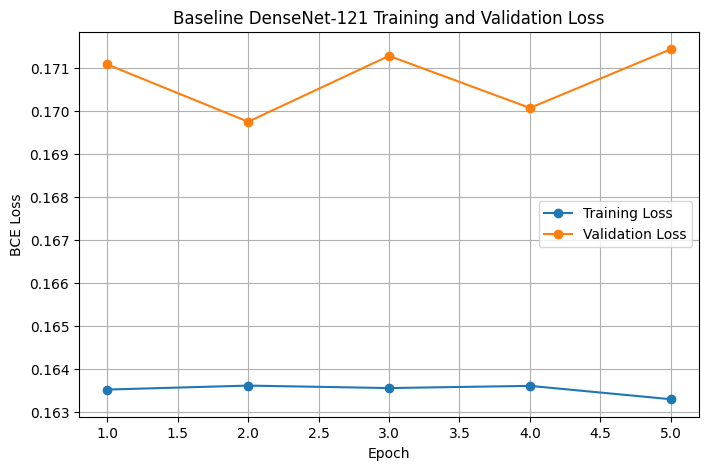

In [54]:
# Plot training and validation loss across epochs to visualize model fit.
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker='o',
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel("BCE Loss")
plt.title("Baseline DenseNet-121 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [56]:
# Print the exact loss values so the numerical trend can be revealed
# alongside the learning-curve visualization.
for epoch, (train_loss, val_loss) in enumerate(
    zip(train_losses, val_losses),
    start=1
):
  print(
      f"Epoch {epoch}: "
      f"Train Loss = {train_loss:.4f}, "
      f"Val Loss = {val_loss:.4f}"
  )

Epoch 1: Train Loss = 0.1635, Val Loss = 0.1711
Epoch 2: Train Loss = 0.1636, Val Loss = 0.1698
Epoch 3: Train Loss = 0.1636, Val Loss = 0.1713
Epoch 4: Train Loss = 0.1636, Val Loss = 0.1701
Epoch 5: Train Loss = 0.1633, Val Loss = 0.1714


### Baseline Training Interpretation

Training and validation loss remained stable across the five baseline epochs.

Training loss changed only slightly, from **0.1638 in epoch 1 to 0.1637 in epoch 5**, while validation loss remained between approximately **0.170 and 0.172**. The lowest validation loss was **0.1699 at epoch 4**.

The close training and validation losses provide no clear evidence of overfitting during this baseline run. However, the limited improvement across epochs also suggests that performance has plateaued when only the newly added classifier layer is trained while the pretrained Dense Net feature extractor remains frozen.

That is useful as a basline result. It establishes performance achievable using fixed ImageNet-pretrained features before exploring later improvements such as fine-tuning deeper DenseNet layers, addressing class imbalance, or modifying the image preprocessing strategy.


### Best Model Checkpoint

During training, the model weights were saved whenever validation loss reached a new minimum.

This means the checkpoint used for later evaluation is not automatically the model from epoch 5. Instead, it represents the epoch that achieved the strongest validation loss during training.

The saved checkpoint is verified below before proceeding to model evaluation

In [59]:
# Confirm that the best validation checkpoint was saved succesfully
# to persistent Google Drive storage
best_model_path = model_dir / "densenet121_baseline_best.pth"

print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint exists:", best_model_path.exists())
print("Checkpoint:", best_model_path)

Best validation loss: 0.1698
Checkpoint exists: True
Checkpoint: /content/drive/MyDrive/nih_chestxray14_pytorch/models/densenet121_baseline_best.pth


### Checkpoint Verification Result

The best baseline checkpoint was saved successfully to persistent Google Drive storage.

The lowest validation loss achieved during training was **0.1698**. The corresponding DenseNet-121 weights were preserved in densenet121_baseline_best.pth and will be be reloaded for subsequent model evaluation.

Using the best validation checkpoint ensures that the test-set evaluation is based on the strongest model selected using validation performance rather than simple the final training epoch.